# EDA 01: chất lượng và quy mô dữ liệu

Dữ liệu thô có gì, lỗi ở đâu và bao nhiêu, mỗi user có bao nhiêu dữ liệu. Notebook chỉ mô tả, không đặt ngưỡng.

| Mục | Câu hỏi | Làm căn cứ cho |
|---|---|---|
| 1 | Dữ liệu có gì, chất lượng ra sao (trùng, lỗi tọa độ, lỗi thời gian)? | Bước lọc lỗi dữ liệu, trùng (A2, A3) |
| 2 | Mỗi user có bao nhiêu dữ liệu, chênh lệch thế nào? | Ngưỡng dữ liệu tối thiểu (A11) |
| 3 | Lỗi thời gian; dòng trùng timestamp: bao nhiêu, trùng ở cột nào, lệch bao xa, và nên giữ / bỏ thế nào? File trùng giữa các user | Kiểm tra thời gian, quy tắc bỏ trùng (A3) |

**Cách chạy.** Cần chạy một lần `python src/preprocess/convert_raw.py` trước (chuyển dữ liệu thô sang `data/interim`). Sau đó Run All; notebook nạp dữ liệu từ `data/interim` và tính trong khoảng 1–2 phút. Muốn chạy thử nhanh thì đặt `USERS_LIMIT` ở cell đầu. Trong cùng một phiên, chỉ sửa cell phân tích thì chỉ cần chạy lại cell đó.

**Mục 3.1–3.8 đọc lại file `.plt` gốc** (cần `data/raw/geolife`), vì `data/interim` đã bỏ độ cao và cột ngày. Lần đầu quét mọi user mất khoảng 10 phút; kết quả lưu ở `data/interim/dup_scan/`, các lần sau chỉ đọc lại. Mục 3.6 chạy stay point trên vài user, thêm khoảng 2–3 phút.

Code tính toán nằm trong `src/eda/` (`scan.py`, `config.py`; riêng mục 3.1–3.8 là `duplicates.py`). Mục được đánh số liên tục 1–13 xuyên các notebook; xem bảng ở README.

**Quy ước.** Timestamp gốc là UTC (theo User Guide). "Giờ địa phương" theo giả thuyết ở `src/eda/config.py`, kiểm chứng ở notebook 04 mục 10. Một "bước" là cặp hai điểm liên tiếp của cùng user sau khi sắp xếp theo thời gian và bỏ timestamp trùng.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from eda.config import *          # dữ kiện từ tài liệu, mốc mô tả, bins (xem src/eda/config.py)
from eda.utils import pct, hist_quantile, qtable, fmt_s
from eda.scan import run
from eda import split

USERS_LIMIT = split.dev_users()   # nhóm dev (D17); đặt None để chạy mọi user (không dùng để chọn ngưỡng)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

R = run(topics=[], users=USERS_LIMIT)
users, files, A = R.users, R.files, R.A

print(f"{len(users)} user, {len(files):,} file")

[20/122] đã đọc tới user 031 (4 giây)
[40/122] đã đọc tới user 058 (7 giây)
[60/122] đã đọc tới user 091 (9 giây)
[80/122] đã đọc tới user 117 (10 giây)
[100/122] đã đọc tới user 147 (13 giây)
[120/122] đã đọc tới user 177 (15 giây)
[122/122] đã đọc tới user 179 (16 giây)
122 user, 13,022 file


## 1. Tổng quan và chất lượng dữ liệu

**Câu hỏi:** dữ liệu có bao nhiêu, và bao nhiêu phần trăm có vấn đề?

- `n_raw`: số dòng đọc được từ file.
- `n_bad_coord`: tọa độ ngoài phạm vi hợp lệ.
- `n_nat`: timestamp không đọc được.
- `n_dup`: timestamp trùng trong cùng user (giữ bản đầu).
- `n_bad_time`: timestamp ngoài 04/2007–08/2012 (khoảng thu thập theo User Guide).

In [2]:
n_raw = users["n_raw"].sum()
print(f"User: {len(users)}  |  File: {len(files):,}  |  User có nhãn phương tiện: {int(users['has_labels'].sum())}")
print(f"Điểm thô: {n_raw:,}  |  Sau khi bỏ trùng: {users['n_points'].sum():,}  |  Bước: {int(A['n_steps']):,}")
print(f"Thời gian (thô): {users['start'].min()} đến {users['end'].max()}")
print(f"Thời gian (hợp lệ): {users['start_valid'].min()} đến {users['end_valid'].max()}")

quality = pd.DataFrame({"số_điểm": users[["n_bad_coord", "n_nat", "n_dup", "n_bad_time"]].sum()})
quality["tỷ_lệ_%"] = quality["số_điểm"] / n_raw * 100
quality["số_user_bị"] = (users[["n_bad_coord", "n_nat", "n_dup", "n_bad_time"]] > 0).sum()
quality.round(4)

User: 122  |  File: 13,022  |  User có nhãn phương tiện: 47
Điểm thô: 17,287,789  |  Sau khi bỏ trùng: 16,859,444  |  Bước: 16,859,322
Thời gian (thô): 2007-04-12 10:18:53+00:00 đến 2012-06-17 16:51:05+00:00
Thời gian (hợp lệ): 2007-04-12 10:18:53+00:00 đến 2012-06-17 16:51:05+00:00


,số_điểm,tỷ_lệ_%,số_user_bị
n_bad_coord,0,0.0000,0
n_nat,0,0.0000,0
n_dup,428345,2.4777,52
n_bad_time,0,0.0000,0


### 1.1 File

Mỗi file `.plt` thường là một lần bật ghi. Thời lượng file cho biết user ghi liên tục cả ngày hay chỉ ghi từng chuyến đi.

,n_points,duration_min
count,13022.0,13022.0
mean,1327.6,150.7
std,2889.0,244.9
min,3.0,0.0
10%,68.0,7.4
50%,503.0,41.4
90%,3293.0,488.0
99%,11344.0,1017.0
max,92645.0,4223.6


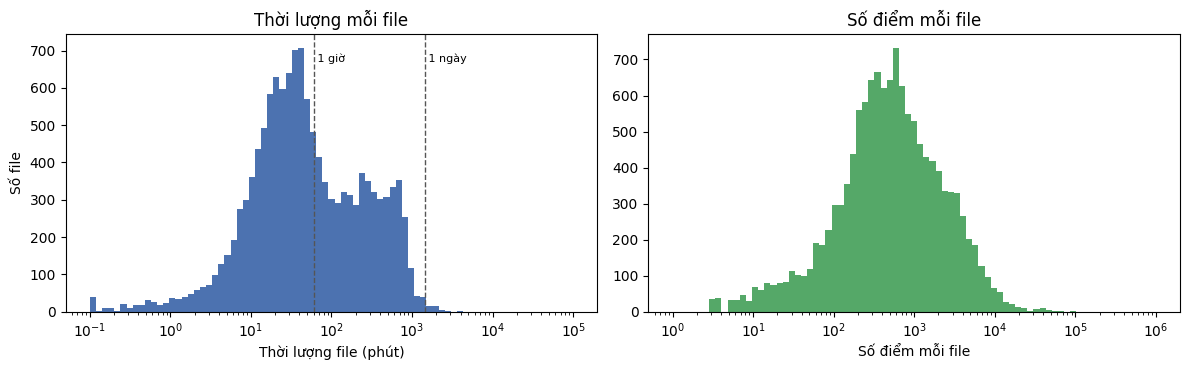

File dài hơn 12 giờ: 559 / 13,022


In [3]:
display(files[["n_points", "duration_min"]].describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
d = files["duration_min"].clip(lower=0.1)
axes[0].hist(d, bins=np.logspace(-1, 5, 80), color="#4c72b0")
axes[0].set_xscale("log")
for x, lab in ((60, "1 giờ"), (1440, "1 ngày")):
    axes[0].axvline(x, color="#555", ls="--", lw=1)
    axes[0].text(x, axes[0].get_ylim()[1] * 0.9, f" {lab}", fontsize=8)
axes[0].set_xlabel("Thời lượng file (phút)")
axes[0].set_ylabel("Số file")
axes[0].set_title("Thời lượng mỗi file")
axes[1].hist(files["n_points"].clip(lower=1), bins=np.logspace(0, 6, 80), color="#55a868")
axes[1].set_xscale("log")
axes[1].set_xlabel("Số điểm mỗi file")
axes[1].set_title("Số điểm mỗi file")
plt.tight_layout()
plt.show()
print(f"File dài hơn 12 giờ: {(files['duration_min'] > 720).sum()} / {len(files):,}")

## 2. Quy mô dữ liệu theo user

**Câu hỏi:** mỗi user có bao nhiêu dữ liệu, có chênh lệch lớn không, và user nào quá ít để suy ra home/office?

- `n_days`: số ngày (giờ địa phương) có ít nhất một điểm.
- `span_days`: từ điểm hợp lệ đầu tiên đến cuối cùng, tính bằng ngày (có phần lẻ).
- `n_span_days`: số ngày địa phương từ ngày đầu đến ngày cuối, tính cả hai đầu.
- `active_ratio`: `n_days / n_span_days`, luôn trong (0, 1]. Hai đại lượng cùng đếm theo ngày địa phương; nếu chia cho `span_days` (tính theo UTC) thì user ghi vắt qua nửa đêm sẽ có tỷ lệ > 1. Gần 1 là ghi gần như mỗi ngày, gần 0 là ghi rải rác.

In [4]:
users[["n_files", "n_points", "n_days", "span_days", "active_ratio", "data_hours"]].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2)


,n_files,n_points,n_days,span_days,active_ratio,data_hours
count,122.00,122.00,122.00,122.00,122.00,122.00
mean,106.74,138192.16,62.43,174.54,0.55,120.67
std,284.79,293919.91,147.23,317.17,0.30,248.31
min,1.00,17.00,1.00,0.00,0.01,0.13
10%,3.00,583.90,3.00,2.48,0.16,3.49
25%,8.00,2971.50,7.00,9.25,0.30,8.85
50%,26.50,23174.50,22.00,61.51,0.53,31.52
75%,89.25,123844.00,60.50,164.26,0.80,111.13
90%,196.60,389383.60,123.40,411.39,1.00,360.47
max,2153.00,2156964.00,1252.00,1793.49,1.00,1639.05


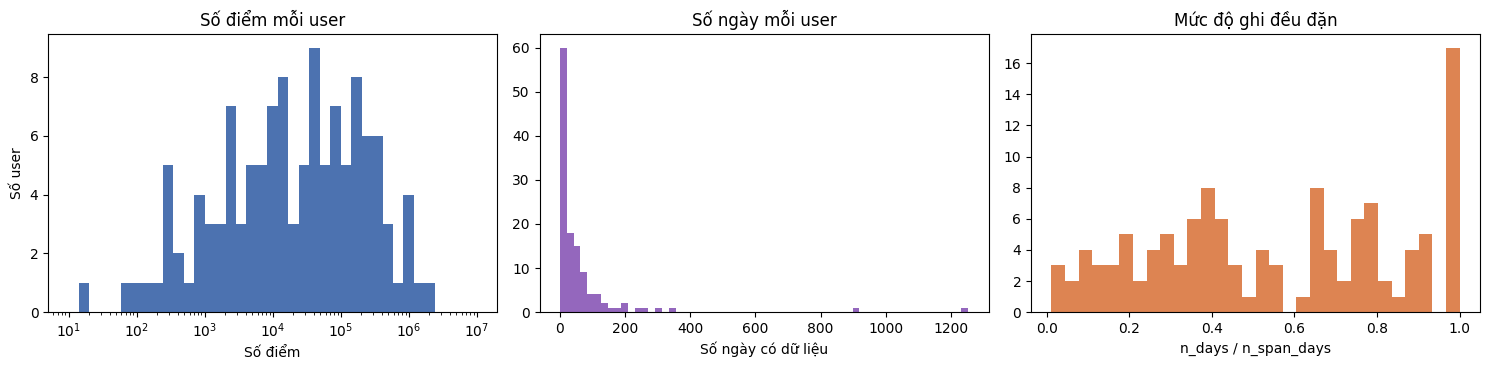

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(users["n_points"].clip(lower=1), bins=np.logspace(1, 7, 40), color="#4c72b0")
axes[0].set_xscale("log"); axes[0].set_xlabel("Số điểm"); axes[0].set_ylabel("Số user")
axes[0].set_title("Số điểm mỗi user")
axes[1].hist(users["n_days"], bins=60, color="#9467bd")
axes[1].set_xlabel("Số ngày có dữ liệu"); axes[1].set_title("Số ngày mỗi user")
axes[2].hist(users["active_ratio"], bins=30, color="#dd8452")
axes[2].set_xlabel("n_days / n_span_days"); axes[2].set_title("Mức độ ghi đều đặn")
plt.tight_layout()
plt.show()

**Độ tập trung:** nếu vài user chiếm phần lớn dữ liệu, các thống kê gộp (phân vị tốc độ, heatmap) chủ yếu phản ánh những user đó.

In [6]:
s = users["n_points"].sort_values(ascending=False).to_numpy()
cum = np.cumsum(s) / s.sum() * 100
for k in [x for x in (1, 5, 10, 20, 50) if x <= len(s)]:
    print(f"Top {k:>2} user chiếm {cum[k - 1]:5.1f}% số điểm")
users.nlargest(10, "n_points")[["user", "n_points", "n_days", "span_days", "share_bj"]]

Top  1 user chiếm  12.8% số điểm
Top  5 user chiếm  37.9% số điểm
Top 10 user chiếm  56.0% số điểm
Top 20 user chiếm  75.4% số điểm
Top 50 user chiếm  95.6% số điểm


,user,n_points,n_days,span_days,share_bj
105,153,2156964,1252,1793.488854,0.725852
87,128,1208309,911,1426.294375,0.798467
26,041,1057038,138,149.199803,0.981379
9,017,1026176,195,247.111620,0.997561
44,068,937876,295,363.991748,0.955787
5,010,931815,124,595.086354,0.275348
15,025,629891,189,208.385139,0.635515
96,144,582833,340,513.958947,0.484194
13,022,471437,134,198.820949,0.878064
1,004,439397,260,278.512025,0.895962


**User ít dữ liệu:** số user dưới mỗi mức số ngày (các mức chỉ là mốc mô tả). Đây là căn cứ để chọn ngưỡng dữ liệu tối thiểu ở bước gán home/office.


In [7]:
display(pd.DataFrame({f"n_days < {k}": [(users["n_days"] < k).sum()] for k in (2, 3, 7, 14, 30)}, index=["số user"]))
users.nsmallest(10, "n_points")[["user", "n_points", "n_days", "data_hours", "start_valid", "end_valid"]]


,n_days < 2,n_days < 3,n_days < 7,n_days < 14,n_days < 30
số user,2,12,28,49,71


,user,n_points,n_days,data_hours,start_valid,end_valid
40,060,17,2,0.233333,2007-08-18 04:26:05+00:00,2007-08-20 01:59:13+00:00
47,072,81,2,1.166667,2007-07-20 06:49:48+00:00,2007-07-21 03:52:23+00:00
120,178,84,1,0.133333,2010-03-12 17:26:08+00:00,2010-03-12 17:33:08+00:00
56,087,152,6,1.366667,2007-08-15 00:37:06+00:00,2007-08-20 00:54:01+00:00
72,107,199,3,2.900000,2007-10-02 07:33:29+00:00,2007-10-07 01:28:16+00:00
98,146,272,8,3.466667,2007-07-31 13:50:53+00:00,2007-08-09 01:50:08+00:00
58,090,320,6,4.116667,2007-07-22 00:03:41+00:00,2007-07-29 05:05:46+00:00
36,053,336,7,4.850000,2008-04-29 08:21:34+00:00,2008-05-07 12:10:18+00:00
111,162,339,9,4.550000,2007-08-01 00:09:58+00:00,2007-08-10 01:56:05+00:00
79,117,341,6,2.316667,2007-06-21 12:21:40+00:00,2007-07-04 11:55:37+00:00


## 3. Lỗi thời gian và dòng trùng

**Câu hỏi:** điểm có timestamp ngoài 04/2007–08/2012 nằm ở đâu? Dòng trùng timestamp chiếm bao nhiêu, trùng ở cột nào, và nên giữ / bỏ thế nào?

| Mục | Nội dung | Kết luận dùng cho |
|---|---|---|
| 3.1 | Tỷ lệ dòng trùng timestamp | quy mô vấn đề |
| 3.2 | Dòng trùng giống nhau ở cột nào: trùng hoàn toàn hay một phần | R1, R2 |
| 3.3 | Hai kiểu trùng theo cỡ nhóm | hiểu nguồn gốc |
| 3.4 | Lệch gần: có nên thay bằng điểm giữa nhóm không | R3 |
| 3.5 | Lệch xa (> 83 m): vì sao bỏ cả nhóm | R4 |
| 3.6 | Cách giữ dòng có làm đổi stay point không | R3, R4 |
| 3.7 | File trùng giữa các user | R5 |
| 3.8 | Quy tắc chốt và số dòng giữ / bỏ | A3 |

In [8]:
bad = users[users["n_bad_time"] > 0][["user", "n_points", "n_bad_time", "start", "end"]]
display(bad)
bad_files = files[(files["start"] < TIME_MIN) | (files["end"] >= TIME_MAX)]
print(f"File có điểm ngoài 04/2007–08/2012: {len(bad_files)}")
bad_files

,user,n_points,n_bad_time,start,end


File có điểm ngoài 04/2007–08/2012: 0


,user,file,n_points,start,end,duration_min


### 3.1 Tỷ lệ dòng trùng timestamp

Đọc lại file `.plt` gốc của mọi user, đủ 7 trường (lat, lon, cột 0, độ cao, cột ngày, date, time).

- **Nhóm trùng:** các dòng của cùng một user có cùng timestamp.
- **Dòng thừa:** số dòng của nhóm trừ 1, tức số dòng bị bỏ nếu chỉ giữ một dòng mỗi timestamp.
- **Dòng đầu nhóm:** dòng xuất hiện trước tiên trong file, là dòng pipeline đang giữ (A3). Mọi so sánh bên dưới là **so dòng thừa với dòng đầu nhóm**.

In [9]:
import importlib
from eda import duplicates as dups
importlib.reload(dups)   # nạp lại code mới nếu kernel đã import bản cũ

REBUILD_DUP_SCAN = False   # True để đọc lại toàn bộ file .plt gốc (khoảng 10 phút)
# Cache riêng cho nhóm dev (dup_scan_dev); đổi USERS_LIMIT thì xoá thư mục đó
PU, EX = dups.scan_all_users(users=USERS_LIMIT, cache_dir=ROOT / "data" / "interim" / "dup_scan_dev",
                             rebuild=REBUILD_DUP_SCAN)
EX["user"] = EX["user"].astype(str)
n_all, n_extra = int(PU["n_rows"].sum()), len(EX)

ov = pd.DataFrame({"số dòng": {
    "tổng dòng thô": n_all,
    "dòng thuộc nhóm trùng": int(PU["n_in_groups"].sum()),
    "số nhóm trùng (timestamp bị trùng)": int(PU["n_groups"].sum()),
    "dòng thừa": n_extra,
}})
ov["% tổng dòng thô"] = (ov["số dòng"] / n_all * 100).round(2)
print(f"User có dòng trùng: {(PU['n_extra'] > 0).sum()} / {len(PU)}")
ov

[20/122] đã quét tới user 031 (98 giây)
[40/122] đã quét tới user 058 (148 giây)
[60/122] đã quét tới user 091 (201 giây)
[80/122] đã quét tới user 117 (219 giây)
[100/122] đã quét tới user 147 (369 giây)
[120/122] đã quét tới user 177 (468 giây)
[122/122] đã quét tới user 179 (471 giây)
User có dòng trùng: 52 / 122


,số dòng,% tổng dòng thô
tổng dòng thô,17287789,100.00
dòng thuộc nhóm trùng,564842,3.27
số nhóm trùng (timestamp bị trùng),136497,0.79
dòng thừa,428345,2.48


,dòng thừa,dòng thừa % (của user),trùng hoàn toàn %,cỡ nhóm,% tổng dòng thừa (cộng dồn)
user,,,,,
065,307173,72.1,10.0,5,71.7
165,68281,52.2,29.2,5,87.7
179,14084,8.3,100.0,2,90.9
058,11000,44.4,3.9,5,93.5
126,9846,2.3,100.0,2,95.8
125,5944,6.2,100.0,2,97.2
010,3761,0.4,5.3,2,98.1
067,3130,0.8,0.9,5,98.8


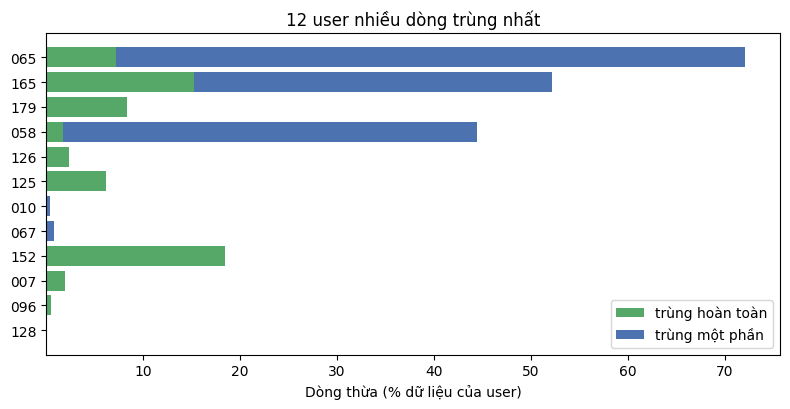

In [10]:
ut = PU[PU["n_extra"] > 0].copy()
ut["dòng thừa % (của user)"] = ut["n_extra"] / ut["n_rows"] * 100
ut["trùng hoàn toàn %"] = EX.groupby("user")["identical"].mean() * 100
ut["cỡ nhóm"] = EX.groupby("user")["group_size"].median().astype(int)
ut = ut.sort_values("n_extra", ascending=False)
ut["% tổng dòng thừa (cộng dồn)"] = ut["n_extra"].cumsum() / n_extra * 100
display(ut.head(8)[["n_extra", "dòng thừa % (của user)", "trùng hoàn toàn %", "cỡ nhóm", "% tổng dòng thừa (cộng dồn)"]]
        .rename(columns={"n_extra": "dòng thừa"}).round(1))

top = ut.head(12).iloc[::-1]
full = top["dòng thừa % (của user)"] * top["trùng hoàn toàn %"] / 100
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index, full, color="#55a868", label="trùng hoàn toàn")
ax.barh(top.index, top["dòng thừa % (của user)"] - full, left=full, color="#4c72b0", label="trùng một phần")
ax.set_xlabel("Dòng thừa (% dữ liệu của user)")
ax.set_title("12 user nhiều dòng trùng nhất")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Đọc kết quả:** dòng thừa chiếm 2,81% dữ liệu nhưng rất tập trung: 3 user 065, 141, 165 chiếm khoảng 89%, và ở 3 user này hơn một nửa dữ liệu là dòng thừa.

### 3.2 Dòng trùng giống nhau ở cột nào

Date và time luôn giống nhau trong nhóm (chúng tạo ra timestamp), nên so 5 trường còn lại bằng chữ gốc. `khớp %` là tỷ lệ dòng thừa có trường đó giống hệt dòng đầu nhóm.

,khớp %,số dòng khác
lat,35.01,278386
lon,30.37,298250
độ cao,99.66,1465
cột 0,100.00,0
cột ngày,100.00,0
lat và lon,20.10,342242
mọi cột (trùng hoàn toàn),20.10,342256


Dòng thừa cùng file với dòng đầu nhóm: 100%  |  nằm ngay sau dòng trước trong file: 100%


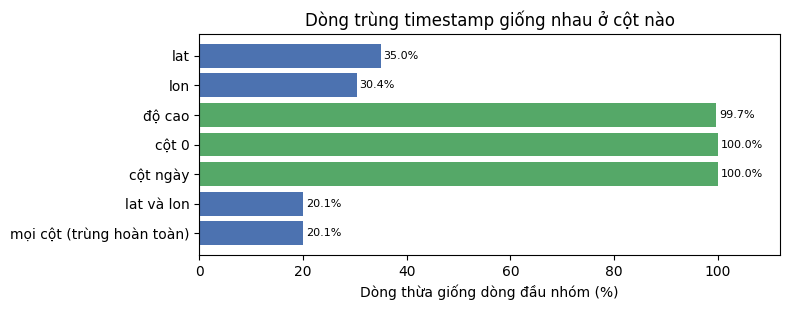

In [11]:
fields = {f"eq_{c}": n for c, n in dups.MATCH_FIELDS.items()}
col = EX[list(fields)].rename(columns=fields)
col["lat và lon"] = EX["eq_lat"] & EX["eq_lon"]
col["mọi cột (trùng hoàn toàn)"] = EX["identical"]
col_tab = pd.DataFrame({"khớp %": col.mean() * 100, "số dòng khác": (~col).sum()})
display(col_tab.round(2))
print(f"Dòng thừa cùng file với dòng đầu nhóm: {EX['same_file'].mean() * 100:.0f}%  |  "
      f"nằm ngay sau dòng trước trong file: {EX['adjacent'].mean() * 100:.0f}%")

fig, ax = plt.subplots(figsize=(8, 3.2))
v = col_tab["khớp %"].iloc[::-1]
bars = ax.barh(v.index, v, color=["#55a868" if x > 99 else "#4c72b0" for x in v])
ax.bar_label(bars, fmt="%.1f%%", fontsize=8, padding=2)
ax.set_xlim(0, 112)
ax.set_xlabel("Dòng thừa giống dòng đầu nhóm (%)")
ax.set_title("Dòng trùng timestamp giống nhau ở cột nào")
plt.tight_layout()
plt.show()

In [12]:
# Trùng hoàn toàn hay một phần: tổ hợp các cột khác dòng đầu nhóm
EX["tổ hợp"] = dups.diff_pattern(EX)
pt = EX.groupby("tổ hợp").agg(dòng_thừa=("user", "size"), khoảng_cách_trung_vị_m=("d_first_m", "median"))
pt.insert(1, "% dòng thừa", pt["dòng_thừa"] / n_extra * 100)
pt.sort_values("dòng_thừa", ascending=False).round(2)

,dòng_thừa,% dòng thừa,khoảng_cách_trung_vị_m
tổ hợp,,,
khác: lat + lon,233045,54.41,1.15
giống hệt,86089,20.10,0.00
khác: lon,63799,14.89,0.43
khác: lat,43947,10.26,0.37
khác: lat + lon + độ cao,1349,0.31,8.96
khác: lon + độ cao,57,0.01,4.61
khác: lat + độ cao,45,0.01,3.89
khác: độ cao,14,0.00,0.00


**Đọc kết quả:**
- Cột 0 và cột ngày luôn giống nhau, độ cao giống ở 99,8%. Phần khác nhau gần như chỉ là **lat, lon**.
- **Trùng hoàn toàn** (giống mọi cột) chiếm 17,5% dòng thừa → quy tắc **R1**: giữ một dòng, không mất thông tin.
- **Chỉ khác độ cao** có 14 dòng → quy tắc **R2**: giữ dòng đầu, vì bài toán không dùng độ cao.
- Còn lại (82%) là **khác lat / lon**, nhưng khoảng cách trung vị dưới 1 m. Mục 3.4–3.5 xem lệch bao xa.
- Mọi dòng thừa nằm cùng file và ngay sau nhau: trùng sinh ra lúc ghi, không phải do hai file chồng nhau.

### 3.3 Hai kiểu trùng

Cỡ nhóm k là số dòng cùng một timestamp (cho k − 1 dòng thừa).

In [13]:
gs = EX.groupby("group_size").agg(dòng_thừa=("user", "size"), trùng_hoàn_toàn_pct=("identical", "mean"))
gs["trùng_hoàn_toàn_pct"] *= 100
gs.insert(1, "% dòng thừa", gs["dòng_thừa"] / n_extra * 100)
gs["user chính"] = EX.groupby("group_size")["user"].agg(lambda s: ", ".join(s.value_counts().index[:4]))
gs.index.name = "cỡ nhóm"
gs.sort_values("dòng_thừa", ascending=False).head(4).round(1)

,dòng_thừa,% dòng thừa,trùng_hoàn_toàn_pct,user chính
cỡ nhóm,,,,
5,385156,89.9,13.2,"065, 165, 058, 067"
2,38334,8.9,89.1,"179, 126, 125, 010"
4,3141,0.7,10.2,"065, 165, 058, 067"
3,1634,0.4,50.9,"152, 065, 165, 058"


**Đọc kết quả:**
- **Cỡ nhóm 5 (92% dòng thừa; 065, 141, 165...):** thiết bị ghi 5 lần mỗi giây nhưng timestamp chỉ tới giây, nên 5 dòng chung một timestamp và lệch nhau chút ít.
- **Cỡ nhóm 2 (179, 167, 126...):** gần như luôn trùng hoàn toàn, tức thiết bị ghi lặp nguyên dòng.

### 3.4 Lệch gần: có nên thay bằng điểm giữa nhóm không

Với dòng thừa khác lat / lon: cách dòng đầu nhóm bao xa? Mốc tham chiếu: ở 300 km/h (ngưỡng outlier A5), 1 giây đi được khoảng **83 m**. Lệch trong mốc này có thể là do ghi nhiều lần trong một giây; lệch xa hơn thì ít nhất một dòng sai (mục 3.5).

,dòng thừa,% dòng khác tọa độ,% cộng dồn
cách dòng đầu nhóm,,,
≤ 1 m,196251,57.343,57.343
1–10 m,143267,41.861,99.204
10–83 m,2568,0.750,99.954
> 83 m,156,0.046,100.000


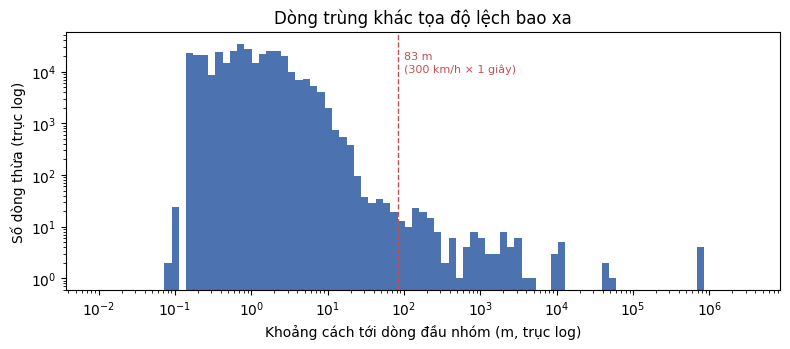

In [14]:
dc = EX[~(EX["eq_lat"] & EX["eq_lon"])]
bins = [0, 1, 10, dups.SAME_SECOND_MAX_M, np.inf]
cut = pd.cut(dc["d_first_m"], bins, labels=["≤ 1 m", "1–10 m", "10–83 m", "> 83 m"], include_lowest=True)
dt = cut.value_counts(sort=False).rename("dòng thừa").to_frame()
dt["% dòng khác tọa độ"] = dt["dòng thừa"] / len(dc) * 100
dt["% cộng dồn"] = dt["% dòng khác tọa độ"].cumsum()
dt.index.name = "cách dòng đầu nhóm"
display(dt.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(dc["d_first_m"].clip(lower=0.01), bins=np.logspace(-2, 6.5, 90), color="#4c72b0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(dups.SAME_SECOND_MAX_M, color="#c44e52", ls="--", lw=1)
ax.text(dups.SAME_SECOND_MAX_M * 1.2, 1e4, "83 m\n(300 km/h × 1 giây)", fontsize=8, color="#c44e52")
ax.set_xlabel("Khoảng cách tới dòng đầu nhóm (m, trục log)")
ax.set_ylabel("Số dòng thừa (trục log)")
ax.set_title("Dòng trùng khác tọa độ lệch bao xa")
plt.tight_layout()
plt.show()

**Thay dòng đầu bằng tâm nhóm (trung bình lat, lon) thì điểm dời đi bao xa?** Đo trên 3 user nhiều trùng nhất. Để so sánh: cột cuối là quãng đi giữa hai giây liên tiếp.

In [15]:
TOP3 = list(ut.index[:3])
rows = {}
for u in TOP3:
    raw = dups.load_user_raw(u)
    cs = dups.center_shift(raw)
    p = raw[raw["ts"].notna()].sort_values(["ts", "file", "row"], kind="stable").drop_duplicates("ts")
    step = pd.Series(dups.haversine_m(p["lat_f"].to_numpy()[:-1], p["lon_f"].to_numpy()[:-1],
                                      p["lat_f"].to_numpy()[1:], p["lon_f"].to_numpy()[1:]))
    step = step[np.diff(p["ts"].to_numpy()).astype("timedelta64[s]").astype(int) == 1]
    rows[u] = {"các dòng cách tâm nhóm, TB (m)": cs["spread_m"].mean(),
               "dòng đầu cách tâm nhóm, TB (m)": cs["shift_m"].mean(),
               "dòng đầu cách tâm nhóm, p95 (m)": cs["shift_m"].quantile(0.95),
               "quãng đi trong 1 giây, TB (m)": step.mean()}
pd.DataFrame(rows).T.round(2)

,"các dòng cách tâm nhóm, TB (m)","dòng đầu cách tâm nhóm, TB (m)","dòng đầu cách tâm nhóm, p95 (m)","quãng đi trong 1 giây, TB (m)"
065,0.94,0.78,2.56,3.81
165,0.54,0.45,2.08,2.15
179,0.00,0.00,0.00,13.53


**Đọc kết quả:** 99,4% dòng khác tọa độ lệch ≤ 10 m. Nếu thay dòng đầu bằng tâm nhóm, điểm chỉ dời trung bình dưới 1 m, nhỏ hơn quãng đi trong 1 giây, nhỏ hơn sai số GPS và rất nhỏ so với bán kính stay 200 m. Tâm nhóm lại là tọa độ không được ghi thật, và bị kéo lệch nếu trong nhóm có một dòng sai. → Quy tắc **R3**: lệch ≤ 83 m thì **giữ dòng đầu**, không lấy trung bình (mục 3.6 xác nhận stay không đổi).

### 3.5 Lệch xa (> 83 m): vì sao bỏ cả nhóm

Với mỗi nhóm có dòng cách dòng đầu hơn 83 m, so từng dòng với điểm liền trước và liền sau trên quỹ đạo (timestamp khác gần nhất). Dòng có tổng khoảng cách tới hai điểm đó nhỏ nhất là dòng "khớp quỹ đạo". Nếu dòng đầu thường là dòng khớp thì giữ dòng đầu là đủ; nếu không thì không có căn cứ chọn dòng nào.

In [16]:
far_users = sorted(EX.loc[EX["d_first_m"] > dups.SAME_SECOND_MAX_M, "user"].unique())
CF = pd.concat([dups.conflict_groups(dups.load_user_raw(u)).assign(user=u) for u in far_users])
GR = dups.group_rules(EX)
n_r4_rows = int(GR.loc[GR["quy tắc"] == "R4", "n_rows"].sum())
display(pd.Series({
    "số nhóm lệch xa": len(CF),
    "số user": len(far_users),
    "số dòng trong các nhóm đó": n_r4_rows,
    "% tổng dòng thô": round(n_r4_rows / n_all * 100, 4),
    "dòng đầu là dòng khớp quỹ đạo (% nhóm)": round(CF["first_is_best"].mean() * 100, 1),
}).to_frame("giá trị"))
print("Ví dụ user 062: hai quỹ đạo cách nhau khoảng 850 km ghi xen kẽ trong cùng một file")
display(CF[CF["user"] == "062"].head(6)[["n_rows", "max_d_first_m", "first_is_best", "d_first_prev_m",
                                         "ở đâu (file:số dòng)"]].round(0))

,giá trị
số nhóm lệch xa,87.0000
số user,11.0000
số dòng trong các nhóm đó,291.0000
% tổng dòng thô,0.0017
dòng đầu là dòng khớp quỹ đạo (% nhóm),37.9000


Ví dụ user 062: hai quỹ đạo cách nhau khoảng 850 km ghi xen kẽ trong cùng một file


,n_rows,max_d_first_m,first_is_best,d_first_prev_m,ở đâu (file:số dòng)
ts,,,,,


**Đọc kết quả, vì sao bỏ cả nhóm (R4):**
1. Lệch hơn 83 m trong cùng 1 giây nghĩa là nhanh hơn 300 km/h (ngưỡng A5; tàu hoả trong dữ liệu chỉ tới khoảng 237 km/h). Hai dòng không thể cùng đúng.
2. Dòng đầu chỉ khớp quỹ đạo ở khoảng 42% số nhóm, gần như tung đồng xu, nên "giữ dòng đầu" sẽ giữ nhầm điểm sai hơn một nửa số lần. Có trường hợp (user 062) chính quỹ đạo xung quanh cũng nhảy, nên cả cách "chọn dòng khớp nhất" cũng không tin được.
3. Đúng nguyên tắc D4: chỉ xoá / giữ khi biết chắc điểm nào sai. Ở đây biết có điểm sai nhưng không biết điểm nào, nên bỏ cả nhóm.
4. Cái giá gần như bằng 0: chỉ khoảng 0,002% dữ liệu (mục 3.6: stay không đổi).

### 3.6 Cách giữ dòng có làm đổi stay point không

Chạy stay point (`stays/detect.py`, D = 200 m, T = 30 phút) trên dữ liệu thô của 3 user nhiều trùng nhất và 2 user nhiều nhóm lệch xa nhất, theo bốn cách:
`first` giữ dòng đầu; `mean` lấy trung bình tọa độ nhóm; `drop_conflict` bỏ mọi nhóm khác tọa độ; `drop_far` giữ dòng đầu nhưng bỏ cả nhóm lệch > 83 m (R3 + R4).

In [17]:
POL = ["first", "mean", "drop_conflict", "drop_far"]
IMP_USERS = TOP3 + list(CF["user"].value_counts().index[:2])
imp = pd.concat([dups.compare_policies(dups.load_user_raw(u), POL).assign(user=u) for u in IMP_USERS])
print("Số stay")
display(imp.pivot(index="user", columns="policy", values="n_stays")[POL])
print("Tổng giờ stay")
imp.pivot(index="user", columns="policy", values="stay_hours")[POL].round(1)

Số stay


policy,first,mean,drop_conflict,drop_far
user,,,,
065,92,91,83,92
128,1050,1049,1050,1050
153,1968,1967,1968,1968
165,30,30,27,30
179,62,62,62,62


Tổng giờ stay


policy,first,mean,drop_conflict,drop_far
user,,,,
065,444.3,430.7,394.0,444.3
128,7029.0,7028.1,7028.6,7028.6
153,13638.2,13637.5,13638.2,13638.2
165,76.1,75.9,63.0,76.1
179,249.3,249.3,249.3,249.3


**Đọc kết quả:** `first`, `mean` và `drop_far` cho số stay gần như bằng nhau, nên lấy trung bình không đem lại gì. `drop_conflict` làm mất stay ở user ghi 5 lần/giây (065, 165), vì nó bỏ cả các nhóm lệch gần hợp lệ, nên loại cách này.

### 3.7 File trùng giữa các user

Bỏ trùng theo timestamp chỉ làm trong từng user, nên không thấy một file bị chép sang user khác. Ở đây so các file **cùng tên** ở nhiều user bằng md5 (giống từng byte). Đây là cận dưới, vì file giống hệt nhưng khác tên không bị phát hiện.

In [18]:
CU = dups.cross_user_groups(progress=False)
cut_tabs = dups.cross_user_tables(CU, PU["n_rows"])
tt = cut_tabs["totals"]
display(pd.Series({"số user có file trùng với user khác": int(tt["số user liên quan"]),
                   "bản sao thừa (file)": int(tt["bản sao thừa (file)"]),
                   "dòng thừa do sao chép": int(tt["dòng thừa do nhân bản"]),
                   "% tổng dòng thô": round(tt["dòng thừa % tổng"], 2)}).to_frame("giá trị"))
print("Cặp user chung nhiều dữ liệu nhất")
display(cut_tabs["pairs"].head(6))
pu_cu = cut_tabs["per_user"]
print("User gần như toàn bộ dữ liệu là bản sao (≥ 90%)")
pu_cu[pu_cu["% dữ liệu của user"] >= 90][["số dòng trong các file đó", "% dữ liệu của user"]].round(1)

,giá trị
số user có file trùng với user khác,52.00
bản sao thừa (file),856.00
dòng thừa do sao chép,1495115.00
% tổng dòng thô,8.65


Cặp user chung nhiều dữ liệu nhất


,số file chung,số dòng chung
153 - 163,225,612042
126 - 167,145,209428
000 - 003,129,160928
010 - 124,10,120113
128 - 153,54,38993
055 - 075,12,37468


User gần như toàn bộ dữ liệu là bản sao (≥ 90%)


,số dòng trong các file đó,% dữ liệu của user
124,120113,100.0
055,37468,99.2
058,23606,95.3
156,16277,100.0
129,16008,98.0
069,16008,97.2
150,2794,100.0
094,2794,100.0
108,484,100.0


**Đọc kết quả:** khoảng 6% dữ liệu là file chép y hệt sang user khác, nhiều hơn cả dòng trùng timestamp. Vì pipeline xử lý theo từng user nên không xoá ở bước làm sạch, mà **gắn cờ** (R5): khi đánh giá hoặc chia dev/test thì chia theo cụm user (`dups.user_components`), và cần quyết định có loại các user gần như toàn bộ là bản sao hay không.

### 3.8 Quy tắc chốt và số dòng giữ / bỏ

| Quy tắc | Điều kiện (so với dòng đầu nhóm cùng timestamp) | Xử lý | Bằng chứng |
|---|---|---|---|
| R1 | Giống mọi cột (trùng hoàn toàn) | Giữ dòng đầu | 3.2: không mất thông tin |
| R2 | Cùng lat, lon; chỉ khác độ cao | Giữ dòng đầu | 3.2: độ cao không dùng |
| R3 | Khác tọa độ, mọi dòng cách dòng đầu ≤ 83 m | Giữ dòng đầu, không lấy trung bình | 3.4: dời < 1 m; 3.6: stay không đổi |
| R4 | Có dòng cách dòng đầu > 83 m | Bỏ cả nhóm | 3.5: không biết dòng nào đúng; dòng đầu chỉ đúng ~42% |
| R5 | File giống hệt ở nhiều user | Không xoá; gắn cờ, chia dev/test theo cụm user | 3.7: ~6% dữ liệu |

Mỗi nhóm được xếp theo dòng "tệ nhất" của nó (có dòng lệch xa thì là R4, dù các dòng khác giống hệt).

So với chỉ giữ dòng đầu (A3 hiện tại, bỏ 428,345 dòng): bỏ thêm 87 dòng


,xử lý,số_nhóm,số_dòng,giữ_lại,bỏ_đi,% tổng dòng thô,giữ lại % tổng,bỏ đi % tổng,bỏ đi % dòng bị bỏ,vì sao
quy tắc,,,,,,,,,,
không trùng,giữ nguyên,0,16722947,16722947,0,96.733,96.733,0.0000,0.00,timestamp chỉ có một dòng
R1,gộp về dòng đầu,41689,105124,41689,63435,0.608,0.241,0.3669,14.81,"giống mọi cột, bỏ dòng lặp không mất thông tin (3.2)"
R2,gộp về dòng đầu,14,28,14,14,0.000,0.000,0.0001,0.00,"cùng tọa độ, chỉ khác độ cao; bài toán không dùng độ cao (3.2)"
R3,gộp về dòng đầu,94707,459399,94707,364692,2.657,0.548,2.1095,85.12,"lệch ≤ 83 m, ghi nhiều lần trong 1 giây; dòng đầu cách tâm nhóm < 1 m, stay không đổi (3.4, 3.6)"
R4,xóa cả nhóm,87,291,0,291,0.002,0.000,0.0017,0.07,lệch > 83 m (> 300 km/h); chắc chắn có dòng sai nhưng không biết dòng nào (3.5)
tổng,,136497,17287789,16859357,428432,100.000,97.522,2.4782,100.00,


,số_dòng,giữ_lại,bỏ_đi,% tổng dòng thô,bỏ đi % tổng
xử lý,,,,,
giữ nguyên,16722947,16722947,0,96.7327,0.0000
gộp về dòng đầu,564551,136410,428141,3.2656,2.4766
xóa cả nhóm,291,0,291,0.0017,0.0017


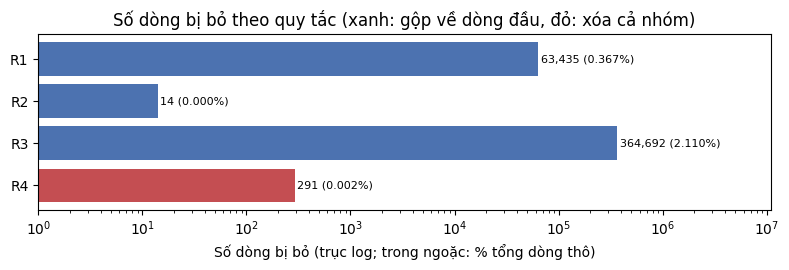

In [19]:
LOẠI = {
    "không trùng": ("giữ nguyên", "timestamp chỉ có một dòng"),
    "R1": ("gộp về dòng đầu", "giống mọi cột, bỏ dòng lặp không mất thông tin (3.2)"),
    "R2": ("gộp về dòng đầu", "cùng tọa độ, chỉ khác độ cao; bài toán không dùng độ cao (3.2)"),
    "R3": ("gộp về dòng đầu", "lệch ≤ 83 m, ghi nhiều lần trong 1 giây; dòng đầu cách tâm nhóm < 1 m, stay không đổi (3.4, 3.6)"),
    "R4": ("xóa cả nhóm", "lệch > 83 m (> 300 km/h); chắc chắn có dòng sai nhưng không biết dòng nào (3.5)"),
}
rt = GR.groupby("quy tắc").agg(số_nhóm=("n_rows", "size"), số_dòng=("n_rows", "sum"),
                               giữ_lại=("kept", "sum"), bỏ_đi=("removed", "sum"))
n_single = n_all - int(rt["số_dòng"].sum())
rt.loc["không trùng"] = [0, n_single, n_single, 0]
rt = rt.loc[list(LOẠI)]
rt.insert(0, "xử lý", [LOẠI[k][0] for k in rt.index])
rt.loc["tổng"] = ["", *rt[["số_nhóm", "số_dòng", "giữ_lại", "bỏ_đi"]].sum()]
rt["% tổng dòng thô"] = rt["số_dòng"] / n_all * 100
rt["giữ lại % tổng"] = rt["giữ_lại"] / n_all * 100
rt["bỏ đi % tổng"] = rt["bỏ_đi"] / n_all * 100
rt["bỏ đi % dòng bị bỏ"] = rt["bỏ_đi"] / rt.loc["tổng", "bỏ_đi"] * 100
rt["vì sao"] = [LOẠI[k][1] if k in LOẠI else "" for k in rt.index]
print(f"So với chỉ giữ dòng đầu (A3 hiện tại, bỏ {n_extra:,} dòng): bỏ thêm {int(rt.loc['tổng', 'bỏ_đi']) - n_extra:,} dòng")
with pd.option_context("display.max_colwidth", 120):
    display(rt.round({"% tổng dòng thô": 3, "giữ lại % tổng": 3, "bỏ đi % tổng": 4, "bỏ đi % dòng bị bỏ": 2}))

# Tổng hợp theo cách xử lý: bao nhiêu % dữ liệu giữ nguyên, gộp, xóa
by = rt.drop("tổng").groupby("xử lý", sort=False)[["số_dòng", "giữ_lại", "bỏ_đi"]].sum()
by["% tổng dòng thô"] = by["số_dòng"] / n_all * 100
by["bỏ đi % tổng"] = by["bỏ_đi"] / n_all * 100
display(by.round(4))

fig, ax = plt.subplots(figsize=(8, 2.8))
x = rt.drop(["tổng", "không trùng"])
bars = ax.barh(x.index[::-1], x["bỏ_đi"].iloc[::-1], color=["#c44e52" if k == "R4" else "#4c72b0" for k in x.index[::-1]])
ax.bar_label(bars, labels=[f"{n:,} ({p:.3f}%)" for n, p in zip(x["bỏ_đi"].iloc[::-1], x["bỏ đi % tổng"].iloc[::-1])],
             fontsize=8, padding=2)
ax.set_xscale("log")
ax.set_xlim(1, x["bỏ_đi"].max() * 30)
ax.set_xlabel("Số dòng bị bỏ (trục log; trong ngoặc: % tổng dòng thô)")
ax.set_title("Số dòng bị bỏ theo quy tắc (xanh: gộp về dòng đầu, đỏ: xóa cả nhóm)")
plt.tight_layout()
plt.show()

**Tóm lại:** R1–R3 chính là cách pipeline đang làm (giữ dòng đầu), áp dụng cho gần như mọi dòng trùng. Thay đổi thật sự chỉ là R4 (bỏ cả nhóm lệch xa, vài trăm dòng) và R5 (gắn cờ file sao chép giữa các user). Ngưỡng 83 m không phải ngưỡng mới mà suy ra từ ngưỡng tốc độ A5 (300 km/h × 1 giây).